# Chen et al. 2021 — Prostate Cancer (10x)
## 02 · Manifold — topology test, curve fit, root, pseudotime

Score the three developmental modules, graph-smooth them for geography, then **test branching honestly**: fit a PPT tree and inspect whether its tips resolve into opposing Gast-high vs pSom-high arms. If not, the manifold is non-branching and we fit a **curve** (not a tree on a strip), root it at the developmental origin (Gast/pSom-high, Crest-low), and verify the fit is **fold-free** off the fitted edges.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold · score developmental modules
`score_genes` for Gast / pSom / Crest against the `union` control pool. Graph-smooth (3× kNN-connectivity averaging) for reading geography and correlations; raw per-cell scores are kept and shown in the deliverables.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print('whole manifold:', adata.shape[0], 'cells | UMAP aspect (major/minor std): %.2f' % (s[0]/s[1]))

feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean score {adata.obs[lab].mean():+.4f}')
# graph-smooth for geography (raw scores retained)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Ssig = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Ssig = A @ Ssig
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = Ssig[:,j]

whole manifold: 14266 cells | UMAP aspect (major/minor std): 1.29
Gast: 75/81 genes present | mean score +0.0043
pSom: 88/98 genes present | mean score +0.0364
Crest: 103/104 genes present | mean score -0.0686


### Geography — smoothed spatial correlations
A single developmental axis shows one dominant inverse gradient; a bifurcation shows a strong Gast↔pSom anti-correlation (the cross-repression axis).

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a:9s} vs {b:9s}: r = {r:+.2f}')
print('per-lobe smoothed developmental means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())

smoothed spatial correlations on the whole manifold:
  Gast_sm   vs pSom_sm  : r = -0.11
  Crest_sm  vs Gast_sm  : r = -0.15
  Crest_sm  vs pSom_sm  : r = -0.76
per-lobe smoothed developmental means:
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0      0.0045   0.0385   -0.0707
1      0.0028   0.0290   -0.0609


### Honest topology test — fit a PPT tree and inspect tip identities
Fit a principal tree; if the manifold truly bifurcates, its tips separate into a **Gast-high arm** and a **pSom-high arm**. If every tip shares one profile, the extra forks are PPT over-fitting a continuous cloud — i.e. non-branching, and a curve is the correct model.

In [5]:
ad_tree = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_tree, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=.5,
                use_rep='X_umap', seed=SEED, plot=False)
B = np.asarray(ad_tree.uns['graph']['B']); F = ad_tree.uns['graph']['F'].T
deg = (B>0).sum(0); tips = np.where(deg==1)[0]; forks = np.where(deg>=3)[0]
R = np.asarray(ad_tree.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print(f'PPT tree (200 nodes): {len(tips)} tips, {len(forks)} forks(deg>=3)')
prof = []
for tp in tips:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    g_,p_,cr_ = ad_tree.obs['Gast_sm'][m].mean(), ad_tree.obs['pSom_sm'][m].mean(), ad_tree.obs['Crest_sm'][m].mean()
    prof.append((g_,p_,cr_)); print(f'  tip {tp:3d} n={int(m.sum()):5d}: Gast={g_:+.3f} pSom={p_:+.3f} Crest={cr_:+.3f}')
prof = np.array(prof)
print(f'\ntip Gast range [{prof[:,0].min():+.3f},{prof[:,0].max():+.3f}] '
      f'pSom range [{prof[:,1].min():+.3f},{prof[:,1].max():+.3f}]')
print('-> all tips share one profile (low Gast, moderate pSom, low Crest): NO opposing arms -> NON-BRANCHING.')

PPT tree (200 nodes): 7 tips, 5 forks(deg>=3)
  tip  17 n=  679: Gast=+0.001 pSom=+0.050 Crest=-0.081
  tip  25 n=  648: Gast=+0.001 pSom=+0.045 Crest=-0.074
  tip  53 n=  614: Gast=+0.007 pSom=+0.030 Crest=-0.075
  tip 115 n=  628: Gast=+0.004 pSom=+0.052 Crest=-0.086
  tip 135 n=  525: Gast=+0.007 pSom=+0.044 Crest=-0.078
  tip 161 n=  665: Gast=+0.000 pSom=+0.015 Crest=-0.045
  tip 189 n=  657: Gast=+0.001 pSom=+0.026 Crest=-0.055

tip Gast range [+0.000,+0.007] pSom range [+0.015,+0.052]
-> all tips share one profile (low Gast, moderate pSom, low Crest): NO opposing arms -> NON-BRANCHING.


### Render the tree edges — visual confirmation there are no arms
Draw the fitted tree over the smoothed pSom / Crest / Gast maps. A true bifurcation would place one tip in a Gast-high region and another in a pSom-high region; here the forks sit inside a single continuous gradient.

cyan = tips, red = forks. Forks lie within one pSom<->Crest gradient, not between opposing arms.


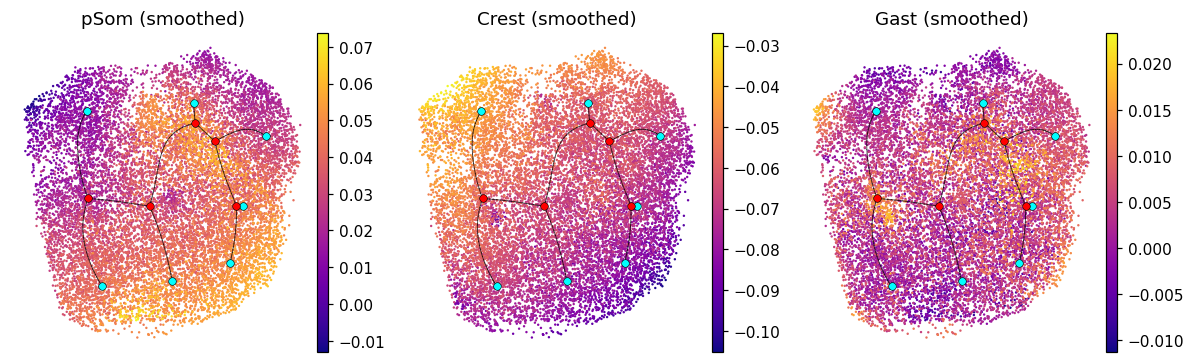

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11,3.4))
for ax,(col,ttl) in zip(axes, [('pSom_sm','pSom (smoothed)'),('Crest_sm','Crest (smoothed)'),('Gast_sm','Gast (smoothed)')]):
    sc.pl.umap(ad_tree, color=col, cmap='plasma', size=10, frameon=False, show=False, ax=ax, title=ttl)
    ii,jj = np.where(np.triu(B>0))
    for a,b in zip(ii,jj): ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]],'-k',lw=0.6,alpha=0.7)
    ax.scatter(F[tips,0],F[tips,1],c='cyan',s=25,zorder=5,edgecolor='k',linewidth=.4)
    ax.scatter(F[forks,0],F[forks,1],c='red',s=25,zorder=5,edgecolor='k',linewidth=.4)
fig.tight_layout()
print('cyan = tips, red = forks. Forks lie within one pSom<->Crest gradient, not between opposing arms.')

### Fit the curve (non-branching model) + fold-free check
`scf.tl.curve` on the integrated UMAP (no re-embedding of a linear compartment). The fold self-approach ratio = (min Euclidean distance between graph-distant nodes) / (median edge length); >1 means no fold.

In [7]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.85 (>1 = fold-free)


### Root at the developmental origin, compute pseudotime
Crest is developmentally **late**, so the root belongs at the Gast/pSom-high, Crest-low tip — never a proliferation state. Root = argmax(Gast+pSom−Crest) over the curve tips.

In [8]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.3f} pSom={info[tp][1]:+.3f} Crest={info[tp][2]:+.3f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s2 in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s2]); print(f'  {s2}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')

tip 0: Gast=+0.003 pSom=+0.023 Crest=-0.055
tip 2: Gast=+0.005 pSom=+0.035 Crest=-0.068
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.177 p=1.1e-100
  pSom_sm: rho=-0.325 p=0.0e+00
  Crest_sm: rho=+0.416 p=0.0e+00
Crest-high decile mean pseudotime = 0.92 (terminal if ~1)


### Orientation for the house linear layout (pseudotime left → right)
The integrated UMAP is reused as-is (identity, no re-embedding); we only flip x if needed so the root (low pseudotime) sits on the left. Milestones are renamed to the developmental poles.

In [9]:
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: identity + x-flip if needed; corr(x_lin, pseudotime) = {r:+.2f}')
scf.tl.rename_milestones(adata, new={str(root): 'Origin (Gast/pSom)',
                                     str(int([tp for tp in tps if tp!=root][0])): 'Crest terminus'})
print('milestones:', list(adata.obs['milestones'].cat.categories))

orientation: identity + x-flip if needed; corr(x_lin, pseudotime) = +0.94
milestones: ['Crest terminus', 'Origin (Gast/pSom)']


### Save manifold + `manifold.pdf` (pseudotime, house strip)

saved manifold.h5ad + manifold.pdf


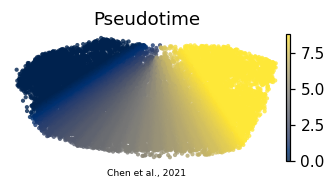

In [10]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}  # sanitize non-serializable entry
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Chen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')